# Using `pyfwg` for direct morphing with `morph_epw_global`, `morph_epw_europe` and `morph_epw_cordex`

This notebook demonstrates the simplest and most direct way to use the `pyfwg` library: the `morph_epw_global`, `morph_epw_europe` and `morph_epw_cordex` functions.

These functions are designed as one-shot tools that provide full access to all of the Future Weather Generator's parameters without requiring the user to manage the multi-step `MorphingWorkflow` class. They handle parameter validation, temporary file management, and final file placement in a single call.

**Supported binaries:** Global 5.2.0, Europe EUR-11 3.2.0 and the other eight CORDEX-CMIP5 distributions 1.2.0. Older Global/Europe releases are outside the supported scope.

**New in pyfwg v0.4.0:** `pyfwg` also supports the **FWG Engine**, the shared engine of the latest distributions of the tool: **Global v5.x**, **Europe v3.x** and the **CORDEX regional** distributions. They are covered in the sections *Using `morph_epw_global` with the FWG Engine (Global v5.x)*, *Europe v3.x (FWG Engine)* and *Using `morph_epw_cordex`*.

Compare with the [direct, simplified version](epw_morph_global_europe_example_simple.ipynb). Both versions retain executed results and plots.


## Configuration

The supported examples use Global 5.2.0, Europe EUR-11 3.2.0 and the other eight CORDEX-CMIP5 distributions 1.2.0. Older Global/Europe releases are outside the supported scope. Download JARs from the [FWG website](https://future-weather-generator.adai.pt/).

Paths are read from environment variables first, then an optional `fwg.local.json` in the project/working folder, then the defaults below. This local JSON file is excluded from Git. JARs can be on an external drive; keep it connected throughout a run. A path containing spaces needs no special escaping in a Python string.

- `FWG_JAR_DIR`: folder of regional JARs (default: project root); keep one version per domain.
- `FWG_GLOBAL_JAR_PATH`: optional full path to Global 5.2.0 if it is in another folder.
- `FWG_EPW_DIR`: real regional baselines named `<domain>.epw`. Global examples use `EUR-11.epw`. Retained validation samples are used if present; otherwise supply `epws/cordex`. Public sample links are in the regional notebook. Do not alter station coordinates to fit a region.
- `FWG_CACHE_DIR`: extracted climate data (default: `~/fwg_model_cache`). EUR-11's full ensemble alone contains about 11.3 GB before extraction overhead. Cache location is independent of the JAR folder.
- `FWG_OUTPUT_DIR`: results, Excel workbooks and diagnostics (default: `build/cordex-tutorial`).
- `FWG_JAVA`: optional Java executable; otherwise Java 17+ must be on PATH.

`RUN_MORPHING = False` prepares every example without starting Java. Set it to `True` to generate weather. Saved outputs include a real execution with `FWG_RUN_MORPHING=1`, the tables and embedded figures. They are visible in Jupyter and Read the Docs without rerunning Java. Set the environment variable to `1` (or set `RUN_MORPHING=True`) to regenerate the examples; otherwise generation stays disabled. Outputs are stored in a separate subfolder for this notebook.


In [1]:
import json
import os
from pathlib import Path
from pyfwg import enable_console_logging

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyfwg" / "__init__.py").is_file()),
    Path.cwd(),
)
local_file = PROJECT_ROOT / "fwg.local.json"
local_paths = json.loads(local_file.read_text(encoding="utf-8")) if local_file.is_file() else {}

def configured_path(name, default):
    return Path(os.environ.get(name, local_paths.get(name, str(default)))).expanduser().resolve()

validation_epws = PROJECT_ROOT / "build/cordex-validation/epws"
default_epws = validation_epws if validation_epws.is_dir() else PROJECT_ROOT / "epws/cordex"
FWG_JAR_DIR = configured_path("FWG_JAR_DIR", PROJECT_ROOT)
FWG_GLOBAL_JAR_PATH = configured_path("FWG_GLOBAL_JAR_PATH", FWG_JAR_DIR / "FutureWeatherGenerator-CMIP6-Global-v5.2.0.jar")
FWG_EPW_DIR = configured_path("FWG_EPW_DIR", default_epws)
FWG_CACHE_DIR = configured_path("FWG_CACHE_DIR", Path.home() / "fwg_model_cache")
FWG_OUTPUT_DIR = configured_path("FWG_OUTPUT_DIR", PROJECT_ROOT / "build/cordex-tutorial")
java_executable = os.environ.get("FWG_JAVA", local_paths.get("FWG_JAVA"))
if java_executable:
    java_path = Path(java_executable).expanduser().resolve()
    if not java_path.is_file():
        raise FileNotFoundError(f"Java executable not found: {java_path}")
    os.environ["PATH"] = str(java_path.parent) + os.pathsep + os.environ.get("PATH", "")
RUN_MORPHING = os.environ.get("FWG_RUN_MORPHING", "0") == "1"
FUTURE_PERIODS = [2050, 2080]
enable_console_logging(level="WARNING")
FWG_OUTPUT_DIR = FWG_OUTPUT_DIR / "epw_morph_global_europe_example"
print("Generation enabled:", RUN_MORPHING)
print("Future climate periods:", FUTURE_PERIODS)
print("Regional JARs:", FWG_JAR_DIR)


Generation enabled: True
Future climate periods: [2050, 2080]
Regional JARs: F:\Python\pyfwg files


### Read a regional JAR and select compatible inputs

This helper reads the actual manifest, including renamed JARs. It selects one model by default, or every ensemble-eligible model with `ensemble=True`, then finds a scenario and period shared by the selection. Empty selections and ambiguous JAR folders fail with an explicit message. The returned dictionary uses the public `pyfwg` parameters; inspect or edit it before running an example.

Caches are separated by distribution ID **and version**, since the same GCM–RCM name can occur in different regions. All examples use `IDW`. `BI`/`1` needs a rectilinear geographic grid and is rejected for these rotated/projected regional grids. One distinct model disables ensemble mode; aliases containing underscores and hyphens refer to the same model. CORDEX Engine distributions do not implement UHI.


In [2]:
from pyfwg import get_fwg_distribution_info

def regional_jar(domain):
    matches = []
    for jar in sorted(FWG_JAR_DIR.glob("*.jar")):
        info = get_fwg_distribution_info(str(jar))
        if info and info["framework"] == "CORDEX" and info["domain"] == domain:
            matches.append((jar, info))
    if len(matches) != 1:
        raise ValueError(f"Expected one {domain} JAR in {FWG_JAR_DIR}; found {len(matches)}. Check the folder and versions.")
    return matches[0]

def regional_inputs(domain, ensemble=False):
    jar, info = regional_jar(domain)
    models = info["ensemble_models"] if ensemble else info["models"][:1]
    if not models or (ensemble and len(models) < 2):
        raise ValueError(f"{domain}: need one model, or at least two eligible models for an ensemble.")
    details = info["model_details"]
    scenarios = [s for s in info["scenarios"] if all(s in details[m]["scenarios"] for m in models)]
    periods = [t for t in info["timeframes"] if all(t in details[m]["timeframes"] for m in models)]
    if not scenarios or not periods:
        raise ValueError(f"{domain}: selected models have no shared scenario or period.")
    if not set(map(str, FUTURE_PERIODS)).issubset(periods):
        raise ValueError("Requested periods are not shared by the selected models.")
    epw = FWG_EPW_DIR / f"{domain}.epw"
    if not epw.is_file():
        raise FileNotFoundError(f"Supply a real baseline inside {domain} at {epw}, or set FWG_EPW_DIR.")
    options = dict(
        epw_paths=str(epw), fwg_jar_path=str(jar),
        fwg_rcm_pairs=list(models), fwg_create_ensemble=ensemble,
        fwg_scenarios=[scenarios[0]], fwg_timeframes=FUTURE_PERIODS,
        fwg_interpolation_method_id="IDW", fwg_output_profile="MINIMAL",
        fwg_model_unzipped_folder=str(FWG_CACHE_DIR / info["distribution_id"] / info["version"]),
        fwg_extra_args={"threads": 1, "io_threads": 1, "save_technical_log": True},
        delete_temp_files=False,
    )
    return info, options


In [3]:
def global_inputs():
    info = get_fwg_distribution_info(str(FWG_GLOBAL_JAR_PATH))
    if not info or info["framework"] != "CMIP" or info.get("domain"):
        raise ValueError(f"Supply a Global FWG Engine JAR at {FWG_GLOBAL_JAR_PATH}")
    epw = FWG_EPW_DIR / "EUR-11.epw"
    if not epw.is_file():
        raise FileNotFoundError(f"Supply the Global example baseline at {epw}")
    model = "CanESM5" if "CanESM5" in info["models"] else info["models"][0]
    details = info["model_details"][model]
    scenario = next(s for s in info["scenarios"] if s in details["scenarios"])
    period = next(t for t in info["timeframes"] if t in details["timeframes"])
    if not set(map(str, FUTURE_PERIODS)).issubset(details["timeframes"]):
        raise ValueError("Requested periods are unavailable for this Global model.")
    return info, dict(
        epw_paths=str(epw), fwg_jar_path=str(FWG_GLOBAL_JAR_PATH),
        fwg_gcms=[model], fwg_create_ensemble=False, fwg_add_uhi=False,
        fwg_scenarios=[scenario], fwg_timeframes=FUTURE_PERIODS,
        fwg_interpolation_method_id="IDW", fwg_output_profile="MINIMAL",
        fwg_use_multithreading=False,
        fwg_model_unzipped_folder=str(FWG_CACHE_DIR / info["distribution_id"] / info["version"]),
        fwg_extra_args={"threads": 1, "io_threads": 1, "save_technical_log": True},
        delete_temp_files=False,
    )


## Global 5.2.0: direct API

Inspect the actual catalog before selecting models. This example uses one model, one available SSP and the 2050/2080 periods. The API returns the collected future EPW/STAT paths. Engine distributions do not support UHI or LCZ morphing. Use `get_fwg_parameters_info()` for parameter descriptions.


In [4]:
from pyfwg import morph_epw_global
info_global, global_options = global_inputs()
print(info_global["name"], info_global["version"])
print("Models:", info_global["models"])
print("Selection:", global_options)
if RUN_MORPHING:
    created_files = morph_epw_global(
        **global_options, output_dir=str(FWG_OUTPUT_DIR / "global-api"),
        temp_base_dir=str(FWG_OUTPUT_DIR / "temp-global-api"),
    )
    print(created_files)
else:
    print("Configuration only; set RUN_MORPHING=True to generate weather.")


FWG CMIP6 Global 5.2.0
Models: ['BCC-CSM2-MR', 'CanESM5', 'CanESM5-1', 'CanESM5-CanOE', 'CAS-ESM2-0', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-CM6-1-HR', 'CNRM-ESM2-1', 'EC-Earth3', 'EC-Earth3-Veg', 'EC-Earth3-Veg-LR', 'FGOALS-g3', 'GFDL-ESM4', 'GISS-E2-1-G', 'GISS-E2-1-H', 'GISS-E2-2-G', 'IPSL-CM6A-LR', 'MIROC-ES2H', 'MIROC-ES2L', 'MIROC6', 'MRI-ESM2-0', 'UKESM1-0-LL']
Selection: {'epw_paths': 'D:\\Python\\pyfwg\\build\\cordex-validation\\epws\\EUR-11.epw', 'fwg_jar_path': 'F:\\Python\\pyfwg files\\FutureWeatherGenerator-CMIP6-Global-v5.2.0.jar', 'fwg_gcms': ['CanESM5'], 'fwg_create_ensemble': False, 'fwg_add_uhi': False, 'fwg_scenarios': ['ssp126'], 'fwg_timeframes': [2050, 2080], 'fwg_interpolation_method_id': 'IDW', 'fwg_output_profile': 'MINIMAL', 'fwg_use_multithreading': False, 'fwg_model_unzipped_folder': 'D:\\Python\\pyfwg\\build\\fwg-cache\\fwg-cmip6-global\\5.2.0', 'fwg_extra_args': {'threads': 1, 'io_threads': 1, 'save_technical_log': True}, 'delete_temp_files': False}

          M

['D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\global-api\\ESP_-_SEVILLA_CanESM5_ssp126_2050.epw', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\global-api\\ESP_-_SEVILLA_CanESM5_ssp126_2050.stat', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\global-api\\ESP_-_SEVILLA_CanESM5_ssp126_2080.epw', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\global-api\\ESP_-_SEVILLA_CanESM5_ssp126_2080.stat']


### Europe v3.x (FWG Engine)

Europe EUR-11 v3.2.0 has passed real generation checks with a single model and its seven-member ensemble. It can be used with `morph_epw_europe` or `morph_epw_cordex`. Run Configuration and the regional helper above, then this section.

The example starts with one model, one shared scenario and the 2050/2080 periods. Set `ensemble=True` to use all eligible members, allowing at least 11.3 GB for climate data plus extraction overhead. Supply `EUR-11.epw` in `FWG_EPW_DIR` and set `RUN_MORPHING=True` to execute.


In [5]:
from pyfwg import morph_epw_europe

info_europe, europe_options = regional_inputs("EUR-11", ensemble=False)
print(info_europe["name"], europe_options["fwg_rcm_pairs"], europe_options["fwg_scenarios"])
if RUN_MORPHING:
    created_files_europe_v3 = morph_epw_europe(
        **europe_options,
        output_dir=str(FWG_OUTPUT_DIR / "europe-api"),
        temp_base_dir=str(FWG_OUTPUT_DIR / "temp-europe-api"),
    )
    print(created_files_europe_v3)
    if not created_files_europe_v3:
        raise RuntimeError("No future weather files were collected; inspect the preserved engine diagnostics.")
else:
    print("Configuration inspected; set RUN_MORPHING=True to generate weather.")


FWG CORDEX-CMIP5 Europe (EUR-11) ['CNRM-CERFACS-CNRM-CM5-CNRM-ALADIN63'] ['rcp26']

          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Europe-EUR-11-v3.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\europe-api
  - EPWs to be Morphed (1 files):
    - EUR-11.epw

  For input file: EUR-11.epw
    -> Generated 'rcp26_2050.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\europe-api\rcp26_2050.epw
    -> Generated 'rcp26_2080.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\europe-api\rcp26_2080.epw
Configuration set. Call execute_morphing() to start the process.



-------------------- Executing FWG for EUR-11.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Europe-EUR-11-v3.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\EUR-11.epw -output_folder=D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\temp-europe-api\EUR-11\ -output_layout=ORGANIZED -models=CNRM-CERFACS-CNRM-CM5-CNRM-ALADIN63 -ensemble=false -temp_shift_winter=0.0 -temp_shift_summer=0.0 -smooth_hours=72 -multithread=true -grid_interpolation_method=IDW -epw_dictionary_limits=true -output_type=EPW -scenarios=rcp26 -timeframes=2050,2080 -output_profile=MINIMAL -model_unzipped_folder=D:\Python\pyfwg\build\fwg-cache\fwg-cordex-cmip5-europe-eur-11\3.2.0 -threads=1 -io_threads=1 -save_technical_log=true


['D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\europe-api\\ESP_-_SEVILLA_CNRM_CERFACS_CNRM_CM5_CNRM_ALADIN63_rcp26_2050.epw', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\europe-api\\ESP_-_SEVILLA_CNRM_CERFACS_CNRM_CM5_CNRM_ALADIN63_rcp26_2050.stat', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\europe-api\\ESP_-_SEVILLA_CNRM_CERFACS_CNRM_CM5_CNRM_ALADIN63_rcp26_2080.epw', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\europe-api\\ESP_-_SEVILLA_CNRM_CERFACS_CNRM_CM5_CNRM_ALADIN63_rcp26_2080.stat']


Europe outputs and diagnostics remain in `FWG_OUTPUT_DIR` for inspection. The shared climate cache remains in `FWG_CACHE_DIR`.


In [6]:
print("Europe API output:", FWG_OUTPUT_DIR / "europe-api")


Europe API output: D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\europe-api


## Using `morph_epw_cordex`

`morph_epw_cordex` accepts **all nine CORDEX-CMIP5 domains, including Europe EUR-11 v3+**. The installed JAR's manifest defines its region, models and scenarios. `CORDEX_REGIONS` is a fallback/reference table; use `get_fwg_distribution_info` for the catalog you actually installed. These distributions have no UHI/LCZ options.

The following table lists the domains. The [dedicated regional notebook](cordex_regions_example.ipynb) includes representative locations, tested versions and examples of all three interfaces.


In [7]:
from pyfwg import morph_epw_cordex, CORDEX_REGIONS

for domain, region in CORDEX_REGIONS.items():
    print(domain, region["name"], region["scenarios"])


EUR-11 Europe ['rcp26', 'rcp45', 'rcp85']
MNA-22 Middle East and North Africa ['rcp85']
AFR-22 Africa ['rcp26', 'rcp85']
NAM-44 North America ['rcp45', 'rcp85']
CAM-44 Central America ['rcp26', 'rcp45', 'rcp85']
SAM-44 South America ['rcp26', 'rcp45', 'rcp85']
WAS-22 West & South Asia ['rcp26', 'rcp85']
SEA-22 Southeast Asia ['rcp45', 'rcp85']
AUS-22 Australasia ['rcp26', 'rcp85']


### Run the morphing process

This example uses the Cairo baseline `MNA-22.epw`, because MNA-22 has been tested with an actual station in that region. Change `DOMAIN` and supply the corresponding EPW to use another region. Java checks native spatial coverage. MNA-22 only offers RCP8.5; other regions offer different scenario subsets, which the helper reads from the JAR.

The default selects one model. Set `ensemble=True` for the complete eligible ensemble and `RUN_MORPHING=True` to run the generation cell.


In [8]:
DOMAIN = "MNA-22"
info_cordex, cordex_options = regional_inputs(DOMAIN, ensemble=False)
print(info_cordex["name"], cordex_options["fwg_rcm_pairs"], cordex_options["fwg_scenarios"])
if RUN_MORPHING:
    created_files_cordex = morph_epw_cordex(
        **cordex_options,
        output_dir=str(FWG_OUTPUT_DIR / "direct" / DOMAIN),
        temp_base_dir=str(FWG_OUTPUT_DIR / "temp-direct" / DOMAIN),
    )
    print(created_files_cordex)
    if not created_files_cordex:
        raise RuntimeError("No future weather files were collected; inspect the preserved engine diagnostics.")
else:
    print("Configuration inspected; set RUN_MORPHING=True to generate weather.")


FWG CORDEX-CMIP5 Middle East and North Africa (MNA-22) ['ICHEC-EC-EARTH-SMHI-RCA4'] ['rcp85']

          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Middle-East-and-North-Africa-MNA-22-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\direct\MNA-22
  - EPWs to be Morphed (1 files):
    - MNA-22.epw

  For input file: MNA-22.epw
    -> Generated 'rcp85_2050.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\direct\MNA-22\rcp85_2050.epw
    -> Generated 'rcp85_2080.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\direct\MNA-22\rcp85_2080.epw
Configuration set. Call execute_morphing() to start the process.



-------------------- Executing FWG for MNA-22.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Middle-East-and-North-Africa-MNA-22-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\MNA-22.epw -output_folder=D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\temp-direct\MNA-22\MNA-22\ -output_layout=ORGANIZED -models=ICHEC-EC-EARTH-SMHI-RCA4 -ensemble=false -temp_shift_winter=0.0 -temp_shift_summer=0.0 -smooth_hours=72 -multithread=true -grid_interpolation_method=IDW -epw_dictionary_limits=true -output_type=EPW -scenarios=rcp85 -timeframes=2050,2080 -output_profile=MINIMAL -model_unzipped_folder=D:\Python\pyfwg\build\fwg-cache\fwg-cordex-cmip5-middle-east-and-north-africa-mna-22\1.2.0 -threads=1 -io_threads=1 -save_technical_log=true


['D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\direct\\MNA-22\\EGY_QH_Cairo.Intl.AP_ICHEC_EC_EARTH_SMHI_RCA4_rcp85_2050.epw', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\direct\\MNA-22\\EGY_QH_Cairo.Intl.AP_ICHEC_EC_EARTH_SMHI_RCA4_rcp85_2050.stat', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\direct\\MNA-22\\EGY_QH_Cairo.Intl.AP_ICHEC_EC_EARTH_SMHI_RCA4_rcp85_2080.epw', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\epw_morph_global_europe_example\\direct\\MNA-22\\EGY_QH_Cairo.Intl.AP_ICHEC_EC_EARTH_SMHI_RCA4_rcp85_2080.stat']


### Inspect results, SolarQC and disk usage

For EPW output, each selected scenario/period normally produces a future EPW and its STAT. The API returns their paths; workflows move and rename them into `final_output_dir`. Check that files exist: a failed Java run is logged and may leave an empty result list. A preview alone does not establish that the EPW passes the engine's checks.

These examples keep `delete_temp_files=False` and technical logs. For SolarQC rejection, inspect `<temp_base_dir>/<EPW stem>/metadata/solarqc_preprocessing_failure.txt` and the `logs/application` folder. During the 2026-10-28 integration checks, New Delhi and Suvarnabhumi samples were rejected; unmodified public Mumbai and Singapore samples passed. Changing the JAR or station coordinates is not a repair for an unsuitable baseline. `MINIMAL` reduces auxiliary output; mandatory diagnostics can still be written.

After reviewing results and diagnostics, you can remove the corresponding temporary directory and the **specific distribution/version cache** when no run is using it. `delete_temp_files=True` removes per-EPW temporary files after a successful run; it does not clear a separately configured shared cache. No cleanup cell in these regional examples removes your results or caches automatically. An iterator reuses caches but does not evict previous regions: with limited space, run one region at a time and clean its cache before continuing.

The downloaded TMYx test samples cover 2009–2023, whereas the CORDEX climate reference period is 1976–2005. FWG reports this mismatch. These are software integration examples; choose and assess the baseline/reference period for your study. See the [CORDEX regional notebook](cordex_regions_example.ipynb) for the nine-region validation matrix and source links.


In [9]:
print("Regional API output:", FWG_OUTPUT_DIR / "direct" / DOMAIN)


Regional API output: D:\Python\pyfwg\build\cordex-tutorial\epw_morph_global_europe_example\direct\MNA-22


## Compare the original weather with future climates

These plots use the original station EPW and the actual generated future EPWs, for the same location and model selection. Curves show monthly means, not a chronological forecast from the present to 2080. The labels 2050 and 2080 identify FWG's future climate periods. The original EPW is a typical-year baseline, not necessarily the model's reference climatology.

Dry-bulb temperature and relative humidity are averaged over the hourly records. For global horizontal irradiation, hourly Wh/m² are summed by day and daily totals are averaged by month, in kWh/m²/day. Missing-value codes are checked before aggregation. Field definitions follow the [EnergyPlus EPW documentation](https://energyplus.net/assets/nrel_custom/pdfs/pdfs_v24.2.0/AuxiliaryPrograms.pdf). These comparisons illustrate the generated files; they do not resolve baseline/reference-period mismatches or quantify projection uncertainty. PNG, SVG and monthly CSV files are saved alongside the results.


In [10]:
import calendar
import csv
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def read_monthly_climate(path):
    """Read hourly EPW values and aggregate a typical year by calendar month."""
    with Path(path).open(encoding="latin-1") as handle:
        location = next(csv.reader(handle))
    weather = pd.read_csv(path, skiprows=8, header=None, encoding="latin-1",
                          usecols=[1, 2, 3, 6, 8, 13])
    weather.columns = ["month", "day", "hour", "temperature", "humidity", "solar"]
    weather = weather.apply(pd.to_numeric, errors="raise")
    if len(weather) not in (8760, 8784) or weather.duplicated(["month", "day", "hour"]).any():
        raise ValueError(f"Expected a complete hourly typical year: {path}")
    if set(weather.month) != set(range(1, 13)) or set(weather.hour) != set(range(1, 25)):
        raise ValueError(f"Invalid EPW calendar: {path}")
    # EnergyPlus EPW missing-value codes, different for each field.
    weather["temperature"] = weather.temperature.mask(weather.temperature == 99.9)
    weather["humidity"] = weather.humidity.mask(weather.humidity == 999)
    weather["solar"] = weather.solar.mask(weather.solar == 9999)
    missing = weather[["temperature", "humidity", "solar"]].isna().sum()
    if missing.any():
        raise ValueError(f"Missing weather values; review the EPW before comparison: {missing.to_dict()}")
    daily_hours = weather.groupby(["month", "day"]).size()
    if not daily_hours.eq(24).all():
        raise ValueError(f"Incomplete days in {path}")
    monthly = weather.groupby("month")[["temperature", "humidity"]].mean()
    # EPW solar values are Wh/m2 per hour: sum each day, then average days.
    daily_solar = weather.groupby(["month", "day"])["solar"].sum(min_count=24) / 1000
    monthly["solar"] = daily_solar.groupby("month").mean()
    return monthly, weather.temperature.mean(), location

def compare_climates(baseline_path, future_paths, title, figure_name):
    baseline, baseline_annual, location = read_monthly_climate(baseline_path)
    datasets = {"Original EPW": baseline}
    annual = {"Original EPW": baseline_annual}
    for path in future_paths:
        match = re.search(r"((?:rcp|ssp)\d+)_(2050|2080)", Path(path).stem, re.I)
        if match is None:
            raise ValueError(f"Scenario/period missing from output filename: {path}")
        label = f"{match[1].upper()} · {match[2]}"
        if label in datasets:
            raise ValueError("Use a separate comparison for each model/parameter selection.")
        monthly, annual_temperature, projected_location = read_monthly_climate(path)
        if not np.allclose([float(location[i]) for i in (6, 7)],
                           [float(projected_location[i]) for i in (6, 7)], atol=1e-4, rtol=0):
            raise ValueError("Baseline and projection must describe the same station.")
        datasets[label] = monthly
        annual[label] = annual_temperature
    if len(datasets) == 1:
        raise ValueError("Generate future EPWs before plotting.")
    colors = ["#243746", "#0072B2", "#D55E00"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
    for index, (label, monthly) in enumerate(datasets.items()):
        style = dict(color=colors[index % len(colors)], linewidth=2.2,
                     marker="o" if index else None, markersize=4, label=label)
        axes[0, 0].plot(monthly.index, monthly.temperature, **style)
        axes[1, 0].plot(monthly.index, monthly.humidity, **style)
        axes[1, 1].plot(monthly.index, monthly.solar, **style)
        if index:
            axes[0, 1].plot(monthly.index, monthly.temperature - baseline.temperature, **style)
    axes[0, 1].axhline(0, color="#667788", linewidth=1, linestyle="--")
    panels = [("Mean dry-bulb temperature", "°C"),
              ("Temperature change from original", "Δ°C"),
              ("Mean relative humidity", "%"),
              ("Mean daily global horizontal irradiation", "kWh/m²/day")]
    for ax, (heading, unit) in zip(axes.flat, panels):
        ax.set_title(heading, fontsize=11, loc="left", fontweight="bold")
        ax.set_ylabel(unit)
        ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
        ax.grid(alpha=.2)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, fontsize=15, fontweight="bold", y=.99)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5, .955), ncol=3, frameon=False)
    fig.text(.5, .015, "2050 and 2080 identify FWG climate periods, not individual forecast years. Same station and model selection.",
             ha="center", fontsize=9, color="#465560")
    fig.tight_layout(rect=(0, .035, 1, .89))
    figure_dir = FWG_OUTPUT_DIR / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / f"{figure_name}.png", dpi=160, bbox_inches="tight")
    fig.savefig(figure_dir / f"{figure_name}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    summary = pd.DataFrame({"Annual mean temperature (°C)": annual})
    summary["Change from original (°C)"] = summary.iloc[:, 0] - baseline_annual
    display(summary.round(2))
    pd.concat(datasets, names=["climate", "month"]).to_csv(figure_dir / f"{figure_name}-monthly.csv")


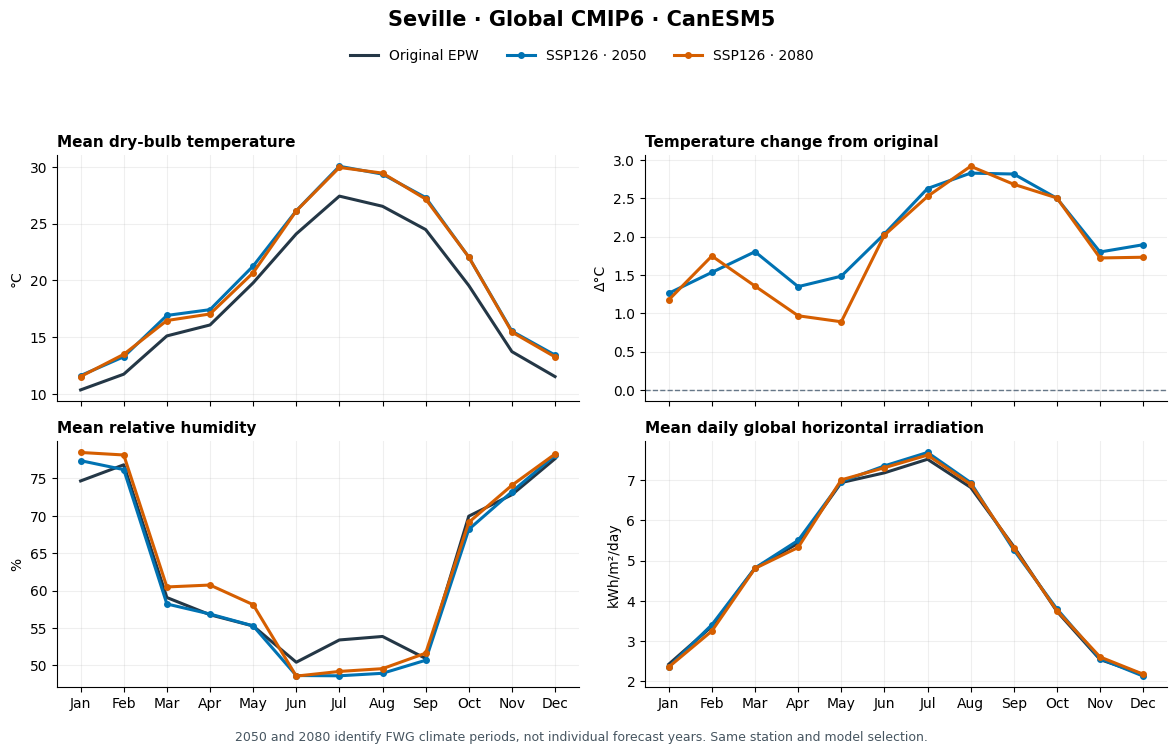

,Annual mean temperature (°C),Change from original (°C)
Original EPW,18.40,0.00
SSP126 · 2050,20.40,2.00
SSP126 · 2080,20.26,1.85


In [11]:
compare_climates(
    FWG_EPW_DIR / "EUR-11.epw", sorted((FWG_OUTPUT_DIR / "global-api").glob("*.epw")),
    "Seville · Global CMIP6 · CanESM5", "seville-global-climate-comparison",
)
